In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
data = pd.read_csv("House Price Prediction Dataset.csv")
data

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119


In [4]:
df = pd.DataFrame(data)

In [5]:
print(df)

        Id  Area  Bedrooms  Bathrooms  Floors  YearBuilt  Location  Condition  \
0        1  1360         5          4       3       1970  Downtown  Excellent   
1        2  4272         5          4       3       1958  Downtown  Excellent   
2        3  3592         2          2       3       1938  Downtown       Good   
3        4   966         4          2       2       1902  Suburban       Fair   
4        5  4926         1          4       2       1975  Downtown       Fair   
...    ...   ...       ...        ...     ...        ...       ...        ...   
1995  1996  4994         5          4       3       1923  Suburban       Poor   
1996  1997  3046         5          2       1       2019  Suburban       Poor   
1997  1998  1062         5          1       2       1903     Rural       Poor   
1998  1999  4062         3          1       2       1936     Urban  Excellent   
1999  2000  2989         5          1       3       1903  Suburban       Fair   

     Garage   Price  
0    

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
# Load the House Price Prediction dataset
data = pd.read_csv("House Price Prediction Dataset.csv")
data
# Display the dataset
df = pd.DataFrame(data)
# Select the input variable for simple linear regression
x_simple = df[["Area"]]
# Select the input variable for multiple linear regression
x_multiple = df[["Area","Bedrooms","Bathrooms","Floors"]]
# Select the output variable (house price)
y_output = df["Price"]
# Split the data into training and testing sets for simple regression
X_train_s, X_test_s, y_train, y_test = train_test_split(x_simple, y_output, test_size=0.2, random_state=42)
# Split the data into training and testing sets for multiple regression
X_train_m, X_test_m, _, _ = train_test_split(x_multiple, y_output, test_size=0.2, random_state=42)
# Create the simple linear regression model
simple_model = LinearRegression()
# Train the simple regression model
simple_model.fit(X_train_s, y_train)
simple_predictions = simple_model.predict(X_test_s)

print("\n--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, simple_predictions)))





--- Simple Linear Regression ---
Intercept: 536693.6793940249
Coefficient: -0.18386104195285685
R2 Score: -0.0007365003351658128
RMSE: 279027.1086887075


In [6]:
# Create the multiple linear regression model
multiple_model = LinearRegression()
# Train the multiple regression model
multiple_model.fit(X_train_m, y_train)
# Predict house prices using the multiple regression model
multiple_predictions = multiple_model.predict(X_test_m)

print("\n--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
print("R2 Score:", r2_score(y_test, multiple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
))



--- Multiple Linear Regression ---
Intercept: 515813.3053297419
Coefficients: [-4.09573189e-01  6.19953164e+00 -9.98415890e+03  2.34561753e+04]
R2 Score: -0.011607381727367194
RMSE: 280538.53428802226


In [15]:
# Create sample input data for predicting a new house price using simple regression
new_house_simple = pd.DataFrame({"Area": [6]})
# Create sample input data for predicting a new house price using multiple regression
new_house_multiple = pd.DataFrame({
    "Area": [6],
    "Bedrooms": [80],
    "Bathrooms": [22],
    "Floors":[2]
})

print("\nPredicted marks using Simple Regression:",
      simple_model.predict(new_house_simple)[0])

print("Predicted marks using Multiple Regression:",
      multiple_model.predict(new_house_multiple)[0])



Predicted marks using Simple Regression: 536692.5762277732
Predicted marks using Multiple Regression: 343567.6652193321


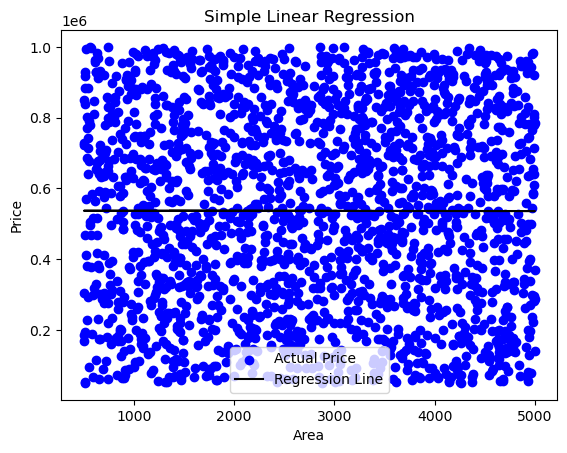

In [17]:
# Plot the actual house prices and the regression line for simple linear regression
plt.scatter(df["Area"], df["Price"],
            color="blue", label="Actual Price")

plt.plot(
    df["Area"],
    simple_model.predict(x_simple),
    color="black",
    label="Regression Line"
)

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()
